In [ ]:
####################againnnnnnnnnnnnnnnnnnscrape2
import arxiv
import pandas as pd
import time
from tqdm import tqdm

def fetch_arxiv_data(max_results=100000, results_per_iteration=500):
    """
    Scrappe les données d'arXiv efficacement
    Args:
        max_results: Nombre total d'articles (entre 10k-20k)
        results_per_iteration: Articles par requête (100-500 recommandé)
    """
    client = arxiv.Client()
    all_results = []
    iterations = max_results // results_per_iteration

    for i in tqdm(range(iterations)):
        try:
            search = arxiv.Search(
                query="cat:cs.*",  # Toutes catégories CS
                max_results=results_per_iteration,
                sort_by=arxiv.SortCriterion.SubmittedDate,
                sort_order=arxiv.SortOrder.Descending
            )

            # Récupération des résultats
            batch_results = []
            for paper in client.results(search):
                batch_results.append({
                    'ID': paper.entry_id.split('/')[-1],
                    'Title': paper.title,
                    'Authors': "|".join([a.name for a in paper.authors]),
                    'Date': paper.published.strftime('%Y-%m-%d'),
                    'Domain': paper.primary_category,
                    'PDF_URL': paper.pdf_url,
                    'Abstract': paper.summary[:2000]  # Tronqué pour Excel
                })

            all_results.extend(batch_results)

            # Sauvegarde temporaire
            if (i + 1) % 5 == 0:  # Toutes les 5 itérations
                pd.DataFrame(all_results).to_csv(f"arxiv_temp_{len(all_results)}.csv", index=False)

            # Respect des limites de l'API
            time.sleep(3)

        except Exception as e:
            print(f"\n⚠️ Erreur à l'itération {i}: {str(e)}")
            time.sleep(30)  # Pause plus longue en cas d'erreur

    # Sauvegarde finale
    final_df = pd.DataFrame(all_results)
    final_df.to_csv("arxiv_final_dataset.csv", index=False)
    print(f"\n✅ {len(final_df)} articles sauvegardés avec succès")
    return final_df

# Paramètres optimisés
dataset = fetch_arxiv_data(
    max_results=15000,  # Nombre cible d'articles
    results_per_iteration=300  # Équilibre stabilité/performance
)

 38%|███▊      | 19/50 [04:28<06:49, 13.22s/it]


⚠️ Erreur à l'itération 19: Page of results was unexpectedly empty (https://export.arxiv.org/api/query?search_query=cat%3Acs.%2A&id_list=&sortBy=submittedDate&sortOrder=descending&start=100&max_results=100)


 48%|████▊     | 24/50 [06:07<07:11, 16.60s/it]


⚠️ Erreur à l'itération 24: Page of results was unexpectedly empty (https://export.arxiv.org/api/query?search_query=cat%3Acs.%2A&id_list=&sortBy=submittedDate&sortOrder=descending&start=100&max_results=100)


 72%|███████▏  | 36/50 [09:05<02:58, 12.74s/it]


⚠️ Erreur à l'itération 36: Page of results was unexpectedly empty (https://export.arxiv.org/api/query?search_query=cat%3Acs.%2A&id_list=&sortBy=submittedDate&sortOrder=descending&start=200&max_results=100)


100%|██████████| 50/50 [12:55<00:00, 15.50s/it]



✅ 14100 articles sauvegardés avec succès


In [ ]:
pip install arxiv

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.3/81.3 kB 2.6 MB/s eta 0:00:00
  Created wheel for sgmllib3k: filename=sgmllib3k-1.0.0-py3-none-any.whl size=6046 sha256=c2c4c70d0e1fae9003db7d0439e028155fada4e9bd00b0b0dcec5da533d00119
  Stored in directory: /root/.cache/pip/wheels/3b/25/2a/105d6a15df6914f4d15047691c6c28f9052cc1173e40285d03
Successfully built sgmllib3k


In [ ]:
import arxiv
import pandas as pd
import time
from tqdm import tqdm
import os
from datetime import datetime

class ArXivScraper:
    def __init__(self):
        # Remove the 'delay' keyword argument as it's not supported by arxiv.Client()
        self.client = arxiv.Client(num_retries=5)
        self.base_query = "all:{}"
        self.categories = [
            "cs.AI", "cs.LG",  # Intelligence artificielle
            "physics.med-ph",   # Physique médicale
            "q-bio.QM",        # Biologie quantitative
            "econ.EM",         # Econométrie
            "math.AP"          # Mathématiques appliquées
        ]
        self.batch_size = 1000  # Articles par catégorie (Note: This variable is not currently used in scrape_category)
        self.max_retries = 3 # Note: num_retries is handled by arxiv.Client()
        self.delay = 2  # secondes entre requêtes (used for time.sleep)

    def scrape_category(self, category, max_results=10000):
        """Scrape une catégorie spécifique avec gestion d'erreurs"""
        articles = []
        query = self.base_query.format(category)

        # Calculate the number of search calls needed based on max_results and the internal batch size of 100
        num_search_calls = max_results // 100 # The loop iterates 100 items per search

        for _ in tqdm(range(num_search_calls), desc=f"Scraping {category}"):
            try:
                search = arxiv.Search(
                    query=query,
                    max_results=100, # max_results for the API call
                    sort_by=arxiv.SortCriterion.SubmittedDate,
                    sort_order=arxiv.SortOrder.Descending
                )

                # The client.results(search) generator handles pagination internally up to max_results of the Search object
                # However, to control the overall number of articles per category and apply delays between search calls,
                # we can loop through the results and explicitly manage batches and delays.
                # The current implementation fetches 100 results per iteration of the outer loop.
                # The arxiv.Client handles retries for the underlying API calls.

                batch_articles = []
                for result in self.client.results(search):
                    batch_articles.append({
                        "id": result.entry_id.split('/')[-1],
                        "title": result.title,
                        "abstract": result.summary,
                        "authors": "|".join([a.name for a in result.authors]),
                        "published": result.published.date(),
                        "updated": result.updated.date(),
                        "doi": result.doi or "",
                        "pdf_url": result.pdf_url,
                        "primary_category": result.primary_category,
                        "categories": "|".join(result.categories),
                        "comment": result.comment[:500] if result.comment else ""
                    })

                articles.extend(batch_articles)

                # Implement delay between consecutive search requests
                time.sleep(self.delay)

            except Exception as e:
                print(f"Erreur avec {category}: {str(e)}")
                time.sleep(10)  # Délai plus long en cas d'erreur

        return pd.DataFrame(articles)

    def save_to_csv(self, df, filename):
        """Sauvegarde incrémentielle"""
        mode = 'a' if os.path.exists(filename) else 'w'
        header = not os.path.exists(filename)

        df.to_csv(
            filename,
            mode=mode,
            header=header,
            index=False,
            encoding='utf-8-sig'
        )

    def run(self, total_articles=100000):
        """Exécution principale"""
        start_time = datetime.now()
        output_file = f"arxiv_articles_{start_time.strftime('%Y%m%d_%H%M')}.csv"

        # Calculate articles per category, ensuring it's a multiple of 100 (the search max_results)
        articles_per_category = (total_articles // len(self.categories) // 100) * 100
        if articles_per_category == 0:
             articles_per_category = 100 # Ensure at least 100 articles are attempted per category if total_articles is small

        print(f"Attempting to scrape {articles_per_category} articles per category.")

        all_scraped_articles = [] # Collect all articles before final save for potential deduplication

        for category in self.categories:
            print(f"\nDébut du scraping pour {category}...")
            df = self.scrape_category(category, articles_per_category)

            if not df.empty:
                all_scraped_articles.append(df)
                print(f"{len(df)} articles collectés pour {category}")
            else:
                print(f"Aucun article trouvé pour {category}")

            time.sleep(5)  # Délai entre catégories

        # Combine and deduplicate all collected articles
        if all_scraped_articles:
            final_df = pd.concat(all_scraped_articles, ignore_index=True).drop_duplicates(subset=["id"])
            self.save_to_csv(final_df, output_file)
            print(f"\n✅ Scraping terminé en {(datetime.now() - start_time).total_seconds()/60:.1f} minutes")
            print(f"Total articles uniques sauvegardés: {len(final_df)}")
            print(f"Fichier sauvegardé: {output_file}")
        else:
             print("\n⚠️ Aucune donnée collectée.")


if __name__ == "__main__":
    scraper = ArXivScraper()

    # Paramètres ajustables :
    scraper.delay = 1.5  # Délai entre les appels de recherche (100 articles)
    # scraper.batch_size = 2000  # This variable is not directly used in the current scrape logic

    scraper.run(total_articles=100000)  # 100k articles total objective

Attempting to scrape 16600 articles per category.

Début du scraping pour cs.AI...


Scraping cs.AI: 100%|██████████| 166/166 [09:30<00:00,  3.44s/it]


16600 articles collectés pour cs.AI

Début du scraping pour cs.LG...


Scraping cs.LG: 100%|██████████| 166/166 [09:29<00:00,  3.43s/it]


16600 articles collectés pour cs.LG

Début du scraping pour physics.med-ph...


Scraping physics.med-ph: 100%|██████████| 166/166 [09:22<00:00,  3.39s/it]


... (3 outputs left out)

Scraping econ.EM: 100%|██████████| 166/166 [09:23<00:00,  3.40s/it]


16600 articles collectés pour econ.EM

Début du scraping pour math.AP...


Scraping math.AP: 100%|██████████| 166/166 [09:13<00:00,  3.34s/it]


16600 articles collectés pour math.AP

✅ Scraping terminé en 56.9 minutes
Total articles uniques sauvegardés: 561
Fichier sauvegardé: arxiv_articles_20250525_2217.csv


Nombre total d'articles : 561
Nombre de catégories uniques : 58
Période couverte : 2025-04-01 à 2025-05-22

Articles avec titres dupliqués : 0
Articles avec résumés dupliqués : 0

Résumés uniques : 561
Pourcentage de résumés uniques : 100.00%

Top 5 catégories :
primary_category
cs.LG             90
math.AP           77
physics.med-ph    71
econ.EM           61
q-bio.QM          51
Name: count, dtype: int64

Longueur moyenne des résumés : 1222.3 caractères

✅ Analyse terminée. Visualisations sauvegardées.


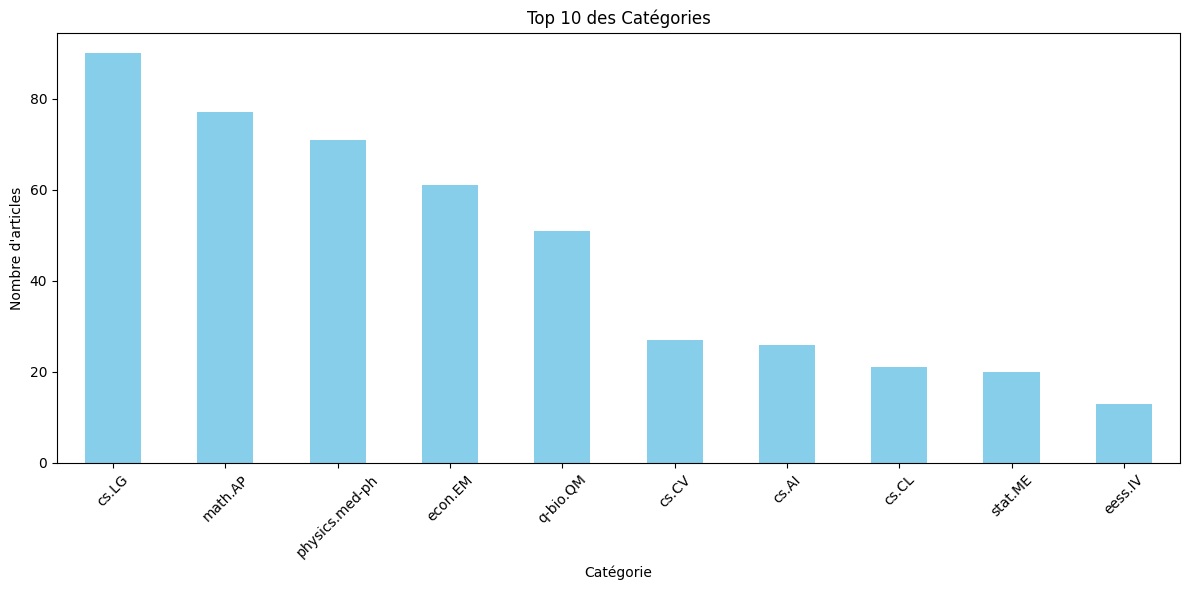

In [ ]:
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt

# 1. Charger les données
df = pd.read_csv('arxiv_articles_20250525_2217.csv')

# 2. Statistiques de base
print(f"Nombre total d'articles : {len(df)}")
print(f"Nombre de catégories uniques : {df['primary_category'].nunique()}")
print(f"Période couverte : {df['published'].min()} à {df['published'].max()}")

# 3. Analyse des doublons
duplicate_titles = df.duplicated(subset=['title']).sum()
duplicate_abstracts = df.duplicated(subset=['abstract']).sum()

print(f"\nArticles avec titres dupliqués : {duplicate_titles}")
print(f"Articles avec résumés dupliqués : {duplicate_abstracts}")

# 4. Résumés uniques (en excluant les vides/nuls)
unique_abstracts = df['abstract'].dropna().nunique()
print(f"\nRésumés uniques : {unique_abstracts}")
print(f"Pourcentage de résumés uniques : {unique_abstracts/len(df)*100:.2f}%")

# 5. Analyse des catégories
category_counts = df['primary_category'].value_counts()
print("\nTop 5 catégories :")
print(category_counts.head())

# 6. Visualisation
plt.figure(figsize=(12, 6))

# Histogramme des catégories
category_counts.head(10).plot(kind='bar', color='skyblue')
plt.title('Top 10 des Catégories')
plt.xlabel('Catégorie')
plt.ylabel('Nombre d\'articles')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('categories_distribution.png')

# 7. Analyse avancée des résumés
abstract_lengths = df['abstract'].str.len()
print("\nLongueur moyenne des résumés : {:.1f} caractères".format(abstract_lengths.mean()))

# 8. Sauvegarde des résultats
with open('arxiv_stats_report.txt', 'w') as f:
    f.write(f"""Rapport d'analyse - Dataset arXiv
{'='*40}
Articles totaux: {len(df)}
Résumés uniques: {unique_abstracts} ({unique_abstracts/len(df)*100:.2f}%)
Période: {df['published'].min()} à {df['published'].max()}
Top catégorie: {category_counts.index[0]} ({category_counts.iloc[0]} articles)
Longueur moyenne résumé: {abstract_lengths.mean():.1f} caractères
""")

print("\n✅ Analyse terminée. Visualisations sauvegardées.")

In [ ]:
import arxiv
import pandas as pd
import time
from tqdm import tqdm
import os
from datetime import datetime

class ArXivScraper:
    def __init__(self):
        self.client = arxiv.Client(num_retries=3)
        self.delay = 3  # Secondes entre requêtes
        self.chunk_size = 100  # Articles par requête
        self.max_articles = 1000  # Max par catégorie (à ajuster)

    def scrape_category(self, category):
        articles = []
        search = arxiv.Search(
            query=f"cat:{category}",
            max_results=self.max_articles,
            sort_by=arxiv.SortCriterion.SubmittedDate,
            sort_order=arxiv.SortOrder.Descending
        )

        for result in tqdm(self.client.results(search), total=self.max_articles, desc=f"Scraping {category}"):
            articles.append({
                "id": result.entry_id.split('/')[-1],
                "title": result.title,
                "abstract": result.summary,
                "published": result.published.date(),
                "category": category
            })
            time.sleep(self.delay)

        return pd.DataFrame(articles)

    def run(self):
        categories = ["cs.AI", "cs.LG", "physics.med-ph", "q-bio.QM", "econ.EM", "math.AP"]
        all_data = []

        for category in categories:
            try:
                df = self.scrape_category(category)
                all_data.append(df)
                print(f"{len(df)} articles scrapés pour {category}")
            except Exception as e:
                print(f"Échec pour {category}: {str(e)}")

        final_df = pd.concat(all_data).drop_duplicates(subset=['id'])
        filename = f"arxiv_full_{datetime.now().strftime('%Y%m%d')}.csv"
        final_df.to_csv(filename, index=False)

        print(f"\n✅ {len(final_df)} articles uniques sauvegardés dans {filename}")

if __name__ == "__main__":
    scraper = ArXivScraper()
    scraper.run()

Scraping cs.AI: 100%|██████████| 1000/1000 [51:04<00:00,  3.06s/it]


1000 articles scrapés pour cs.AI


Scraping cs.LG: 100%|██████████| 1000/1000 [50:57<00:00,  3.06s/it]


1000 articles scrapés pour cs.LG


Scraping physics.med-ph: 100%|██████████| 1000/1000 [51:11<00:00,  3.07s/it]


1000 articles scrapés pour physics.med-ph


... (2 outputs left out)

Scraping econ.EM: 100%|██████████| 1000/1000 [51:26<00:00,  3.09s/it]


1000 articles scrapés pour econ.EM


Scraping math.AP: 100%|██████████| 1000/1000 [50:44<00:00,  3.04s/it]


1000 articles scrapés pour math.AP

✅ 5596 articles uniques sauvegardés dans arxiv_full_20250526.csv


In [ ]:
#########prétraitement

import pandas as pd
import re
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import nltk
from datetime import datetime

# Télécharger les ressources NLTK nécessaires
nltk.download('punkt')
nltk.download('stopwords')

def preprocess_arxiv_data(input_file, output_file):
    """
    Prétraitement complet des données arXiv pour classification.
    Input: fichier CSV contenant 'id', 'title', 'abstract', 'published', 'category'
    Output: fichier CSV avec données prétraitées

    Args:
        input_file (str): Chemin vers le fichier d'entrée CSV
        output_file (str): Chemin vers le fichier de sortie CSV

    Returns:
        tuple: (DataFrame prétraité, vectorizer TF-IDF, label encoder)
    """

    # Étape 1 : Charger les données
    print("Chargement des données...")
    try:
        df = pd.read_csv("arxiv_full_20250526.csv")
    except FileNotFoundError:
        raise FileNotFoundError(f"Le fichier {input_file} n'existe pas. Vérifiez le chemin.")

    # Vérification des colonnes nécessaires
    required_columns = ['id', 'title', 'abstract', 'published', 'category']
    for col in required_columns:
        if col not in df.columns:
            raise ValueError(f"Colonne manquante : {col}")

    # Étape 2 : Gestion des données manquantes
    print("Gestion des données manquantes...")
    df['title'] = df['title'].fillna('')
    df['abstract'] = df['abstract'].fillna('')

    if df['category'].isnull().any():
        print(f"Attention : {df['category'].isnull().sum()} catégories manquantes détectées.")
        df['category'] = df['category'].fillna('unknown')

    if df['published'].isnull().any():
        print(f"Attention : {df['published'].isnull().sum()} dates manquantes détectées.")
        df['published'] = df['published'].fillna(pd.Timestamp('2025-01-01'))

    # Étape 3 : Nettoyage du texte (title et abstract)
    def clean_text(text):
        """
        Nettoyer le texte : minuscules, suppression des caractères spéciaux, espaces inutiles.

        Args:
            text (str): Texte à nettoyer

        Returns:
            str: Texte nettoyé
        """
        text = str(text)
        text = re.sub(r'[^\w\s]', ' ', text)  # Remplacer la ponctuation par des espaces
        text = re.sub(r'\s+', ' ', text)  # Supprimer les espaces multiples
        text = text.lower().strip()  # Minuscules et suppression espaces
        return text

    print("Nettoyage des champs 'title' et 'abstract'...")
    df['title_clean'] = df['title'].apply(clean_text)
    df['abstract_clean'] = df['abstract'].apply(clean_text)

    # Étape 4 : Suppression des mots vides (stop words)
    stop_words = set(stopwords.words('english'))

    def remove_stopwords(text):
        """
        Supprimer les mots vides du texte.

        Args:
            text (str): Texte à traiter

        Returns:
            str: Texte sans stopwords
        """
        try:
            tokens = word_tokenize(text)
            filtered_tokens = [word for word in tokens if word not in stop_words and len(word) > 1]
            return ' '.join(filtered_tokens)
        except Exception as e:
            print(f"Erreur lors de la tokenisation : {str(e)}")
            return text  # Retourner le texte non tokenisé en cas d'erreur

    print("Suppression des mots vides dans 'title' et 'abstract'...")
    df['title_clean'] = df['title_clean'].apply(remove_stopwords)
    df['abstract_clean'] = df['abstract_clean'].apply(remove_stopwords)

    # Étape 5 : Normalisation des dates (champ 'published')
    print("Normalisation des dates...")
    df['published'] = pd.to_datetime(df['published'], errors='coerce')
    df['published'] = df['published'].fillna(pd.Timestamp('2025-01-01'))
    df['year'] = df['published'].dt.year.fillna(2025).astype(int)

    # Étape 6 : Encodage des catégories
    print("Encodage des catégories...")
    label_encoder = LabelEncoder()
    df['category_encoded'] = label_encoder.fit_transform(df['category'])
    category_mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
    print("Mapping des catégories :", category_mapping)

    # Étape 7 : Vectorisation du texte (TF-IDF pour 'abstract_clean')
    print("Vectorisation des résumés avec TF-IDF...")
    vectorizer = TfidfVectorizer(max_features=5000,
                               min_df=5,
                               max_df=0.8,
                               stop_words='english',
                               ngram_range=(1, 2))  # Ajout des bigrammes

    tfidf_matrix = vectorizer.fit_transform(df['abstract_clean'])
    tfidf_df = pd.DataFrame(
        tfidf_matrix.toarray(),
        columns=[f"tfidf_{i}" for i in range(tfidf_matrix.shape[1])],
        index=df.index
    )

    # Étape 8 : Combiner les données prétraitées
    print("Combinaison des données prétraitées...")
    # Sélection des colonnes à conserver
    keep_columns = ['id', 'title_clean', 'abstract_clean', 'published', 'year', 'category', 'category_encoded']
    df = pd.concat([df[keep_columns], tfidf_df], axis=1)

    # Étape 9 : Sauvegarde des données prétraitées
    print(f"Sauvegarde des données prétraitées dans {output_file}...")
    df.to_csv(output_file, index=False)
    print(f"✅ Prétraitement terminé : {len(df)} articles prétraités.")

    return df, vectorizer, label_encoder

# Exemple d'utilisation
if __name__ == "__main__":
    input_file = "arxiv_full_20250527.csv"  # Remplacer par le nom de votre fichier
    output_file = f"arxiv_preprocessed_{datetime.now().strftime('%Y%m%d')}.csv"
    df_preprocessed, vectorizer, label_encoder = preprocess_arxiv_data(input_file, output_file)

#print(f"✅ Prétraitement terminé : {len(df)} articles traités.")


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Le flux de sortie a été tronqué et ne contient que les 5000 dernières lignes.
**********************************************************************

Erreur lors de la tokenisation : 
**********************************************************************
  Resource punkt_tab not found.
  Please use the NLTK Downloader to obtain the resource:

  >>> import nltk
  >>> nltk.download('punkt_tab')
  
  For more information see: https://www.nltk.org/data.html

  Attempted to load tokenizers/punkt_tab/english/

  Searched in:
    - '/root/nltk_data'
    - '/usr/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/local/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/local/lib/nltk_data'
**********************************************************************

Erreur lors de la tokenisation : 
**********************************************************************
  Resource punkt_tab not found.
  Please use the NLTK Downloader to obt

In [ ]:
import pandas as pd

# Charger le fichier
df = pd.read_csv("arxiv_preprocessed_20250528.csv")

# Afficher la taille d'origine
print(f"Nombre d'articles dans le fichier : {len(df)}")

# Vérifier les doublons (par arxiv_id, ou doi, selon ta logique d’unicité)
if 'arxiv_id' in df.columns:
    df_unique = df.drop_duplicates(subset='arxiv_id')
    print(f"Nombre d'articles uniques par 'arxiv_id' : {len(df_unique)}")
elif 'doi' in df.columns:
    df_unique = df.drop_duplicates(subset='doi')
    print(f"Nombre d'articles uniques par 'doi' : {len(df_unique)}")
else:
    df_unique = df.drop_duplicates()
    print(f"Nombre d'articles complètement uniques (toutes colonnes) : {len(df_unique)}")

# Vérification finale
if len(df) == len(df_unique):
    print("✅ Tous les articles sont uniques !")
else:
    print("⚠️ Des doublons existent dans le fichier.")


Nombre d'articles dans le fichier : 5596
Nombre d'articles complètement uniques (toutes colonnes) : 5596
✅ Tous les articles sont uniques !



Nombre exact d'articles par catégorie :
category
cs.AI             1000
math.AP            999
physics.med-ph     996
econ.EM            995
q-bio.QM           978
cs.LG              628
Name: count, dtype: int64

Nombre total d'articles : 5596


<ipython-input-10-0a92d0f10f7e>:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='category', order=df['category'].value_counts().index, palette='viridis')


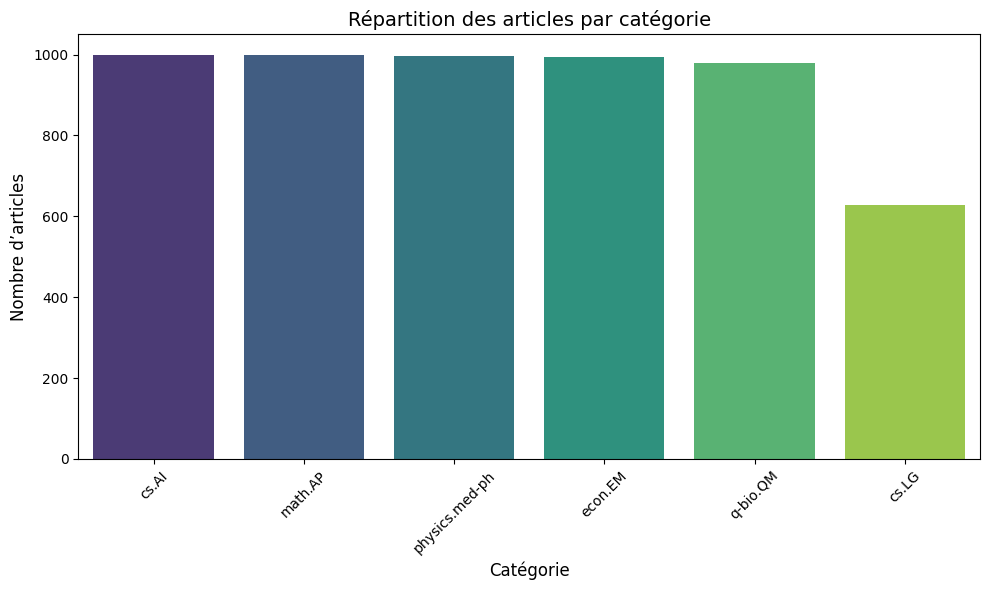

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Charger les données prétraitées
input_file = "arxiv_preprocessed_20250527.csv"  # Remplacer par le nom de votre fichier
try:
    df = pd.read_csv(input_file)
except FileNotFoundError:
    print(f"Erreur : Le fichier {input_file} n'existe pas.")
    exit()

# Vérifier la présence de la colonne 'category'
if 'category' not in df.columns:
    print("Erreur : La colonne 'category' est absente dans le fichier.")
    exit()

# Compter le nombre d'articles par catégorie
category_counts = df['category'].value_counts()
print("\nNombre exact d'articles par catégorie :")
print(category_counts)

# Total des articles
total_articles = len(df)
print(f"\nNombre total d'articles : {total_articles}")

# Visualisation : Histogramme de répartition (déjà généré, mais recréé ici pour référence)
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='category', order=df['category'].value_counts().index, palette='viridis')
plt.title('Répartition des articles par catégorie', fontsize=14)
plt.xlabel('Catégorie', fontsize=12)
plt.ylabel('Nombre d’articles', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('category_distribution_updated.png')
plt.show()

Répartition initiale des catégories :
category
cs.AI             1000
math.AP            999
physics.med-ph     996
econ.EM            995
q-bio.QM           978
cs.LG              628
Name: count, dtype: int64

Répartition après suréchantillonnage :
category
cs.AI             1000
cs.LG             1000
math.AP            999
physics.med-ph     996
econ.EM            995
q-bio.QM           978
Name: count, dtype: int64


<ipython-input-14-157714aaab4c>:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_resampled, order=y_resampled.value_counts().index, palette='viridis')


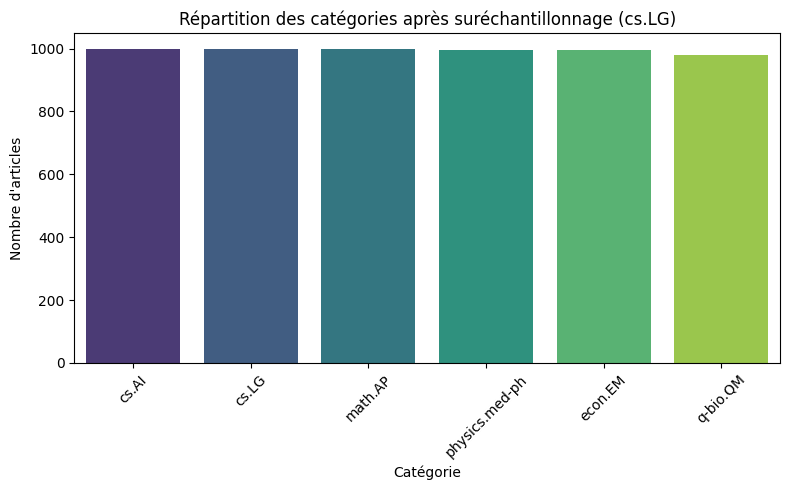

In [ ]:
import pandas as pd
from collections import Counter
from imblearn.over_sampling import RandomOverSampler
import matplotlib.pyplot as plt
import seaborn as sns

# Charger les données (assure-toi que le fichier est bien là)
df = pd.read_csv("arxiv_preprocessed_20250527.csv")  # remplace par ton nom de fichier

# Features (exclure les colonnes non numériques si nécessaire)
X = df.drop(columns=['category'])  # ou garde uniquement les colonnes utiles comme TF-IDF
y = df['category']

# Vérifier la distribution avant suréchantillonnage
print("Répartition initiale des catégories :")
print(y.value_counts())

# Appliquer le suréchantillonnage uniquement sur la classe cs.LG
ros = RandomOverSampler(sampling_strategy={'cs.LG': 1000}, random_state=42)
X_resampled, y_resampled = ros.fit_resample(X, y)

# Créer un DataFrame resamplé si besoin
df_resampled = X_resampled.copy()
df_resampled['category'] = y_resampled

# Afficher la nouvelle répartition
print("\nRépartition après suréchantillonnage :")
print(y_resampled.value_counts())

# Tracer un diagramme de la répartition
plt.figure(figsize=(8, 5))
sns.countplot(x=y_resampled, order=y_resampled.value_counts().index, palette='viridis')
plt.title("Répartition des catégories après suréchantillonnage (cs.LG)")
plt.xlabel("Catégorie")
plt.ylabel("Nombre d'articles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
pip install imbalanced-learn



Nombre d'articles par année :
year
2024    1760
2025    3836
Name: count, dtype: int64


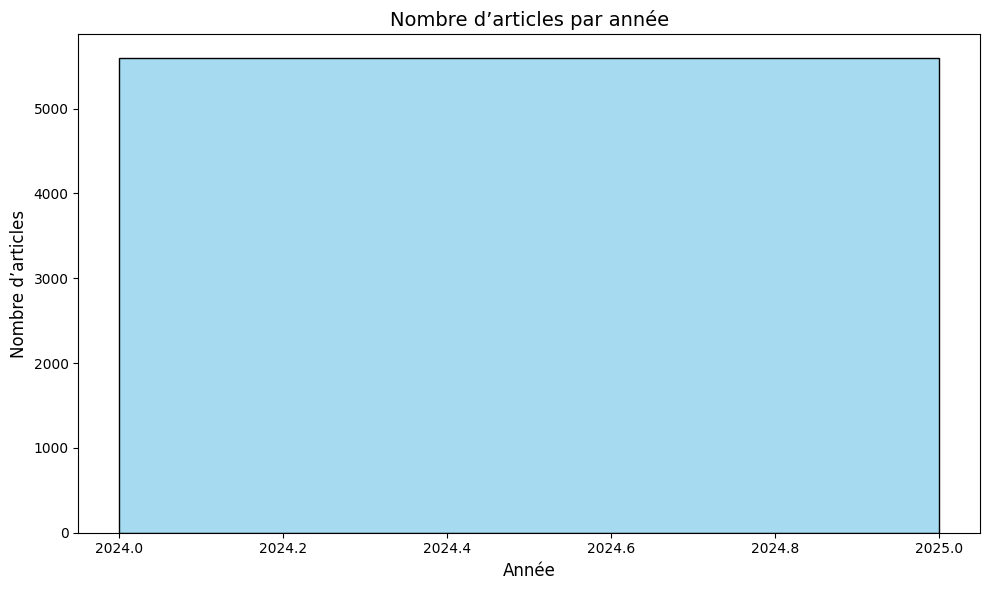


Nombre d'articles par mois (toutes années confondues) :
month
1      259
2      289
3      483
4      780
5     2286
6      144
7      124
8      138
9      252
10     311
11     282
12     248
Name: count, dtype: int64


<ipython-input-11-f852530cf99f>:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='month', palette='viridis')


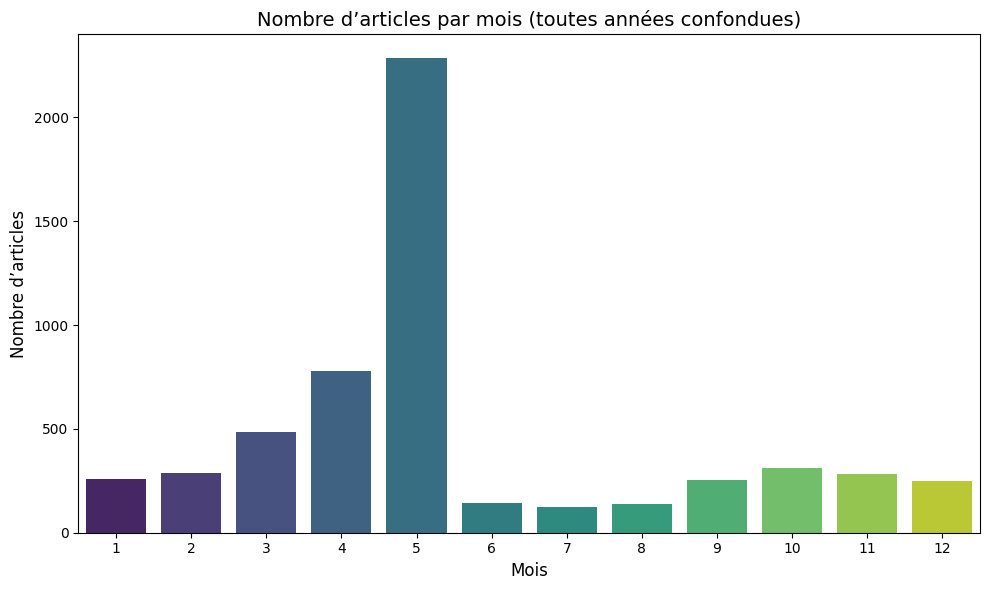


Nombre d'articles par année et mois (YYYY-MM) :
year_month
2024-02      57
2024-03      64
2024-04      63
2024-05      77
2024-06     144
2024-07     124
2024-08     138
2024-09     252
2024-10     311
2024-11     282
2024-12     248
2025-01     259
2025-02     232
2025-03     419
2025-04     717
2025-05    2209
Freq: M, Name: count, dtype: int64


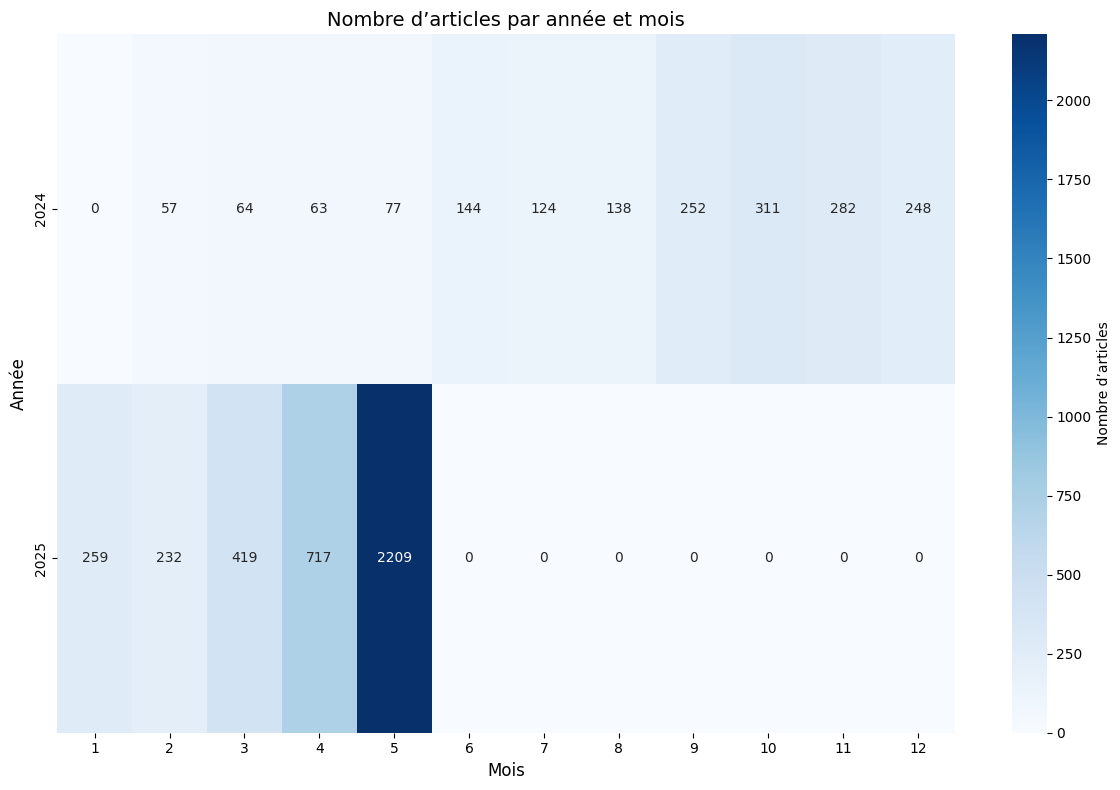

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Charger les données prétraitées
input_file = "arxiv_preprocessed_20250527.csv"  # Remplacer par le nom de votre fichier
try:
    df = pd.read_csv(input_file)
except FileNotFoundError:
    print(f"Erreur : Le fichier {input_file} n'existe pas.")
    exit()

# Vérifier la présence de la colonne 'published'
if 'published' not in df.columns:
    print("Erreur : La colonne 'published' est absente.")
    exit()

# Convertir 'published' en datetime (déjà fait dans le prétraitement, mais au cas où)
df['published'] = pd.to_datetime(df['published'], errors='coerce')

# Extraire l'année et le mois
df['year'] = df['published'].dt.year
df['month'] = df['published'].dt.month
df['year_month'] = df['published'].dt.to_period('M')  # Format 'YYYY-MM'

# 1. Compter le nombre d'articles par année
articles_per_year = df['year'].value_counts().sort_index()
print("\nNombre d'articles par année :")
print(articles_per_year)

# Visualisation : Histogramme des articles par année
plt.figure(figsize=(10, 6))
sns.histplot(df['year'], bins=range(int(df['year'].min()), int(df['year'].max()) + 1), color='skyblue', edgecolor='black')
plt.title('Nombre d’articles par année', fontsize=14)
plt.xlabel('Année', fontsize=12)
plt.ylabel('Nombre d’articles', fontsize=12)
plt.tight_layout()
plt.savefig('articles_per_year.png')
plt.show()

# 2. Compter le nombre d'articles par mois (toutes années confondues)
articles_per_month = df['month'].value_counts().sort_index()
print("\nNombre d'articles par mois (toutes années confondues) :")
print(articles_per_month)

# Visualisation : Histogramme des articles par mois
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='month', palette='viridis')
plt.title('Nombre d’articles par mois (toutes années confondues)', fontsize=14)
plt.xlabel('Mois', fontsize=12)
plt.ylabel('Nombre d’articles', fontsize=12)
plt.tight_layout()
plt.savefig('articles_per_month.png')
plt.show()

# 3. Compter le nombre d'articles par combinaison année-mois
articles_per_year_month = df['year_month'].value_counts().sort_index()
print("\nNombre d'articles par année et mois (YYYY-MM) :")
print(articles_per_year_month)

# Préparer une table pivot pour une heatmap (année vs mois)
pivot_table = df.pivot_table(index='year', columns='month', values='id', aggfunc='count', fill_value=0)

# Visualisation : Heatmap des articles par année et mois
plt.figure(figsize=(12, 8))
sns.heatmap(pivot_table, annot=True, fmt='d', cmap='Blues', cbar_kws={'label': 'Nombre d’articles'})
plt.title('Nombre d’articles par année et mois', fontsize=14)
plt.xlabel('Mois', fontsize=12)
plt.ylabel('Année', fontsize=12)
plt.tight_layout()
plt.savefig('articles_per_year_month_heatmap.png')
plt.show()

<ipython-input-9-76430779d26d>:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_unique, y='category', order=df_unique['category'].value_counts().index, palette='viridis')


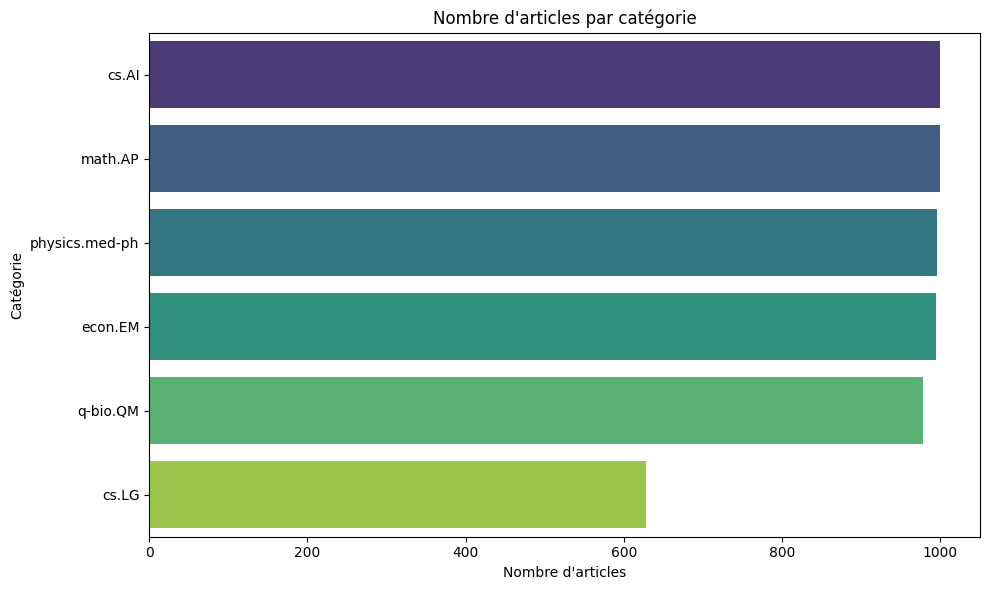

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assure-toi que la colonne 'category' est bien une chaîne de caractères
df_unique['category'] = df_unique['category'].astype(str)

plt.figure(figsize=(10, 6))
sns.countplot(data=df_unique, y='category', order=df_unique['category'].value_counts().index, palette='viridis')
plt.title("Nombre d'articles par catégorie")
plt.xlabel("Nombre d'articles")
plt.ylabel("Catégorie")
plt.tight_layout()
plt.show()


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
<ipython-input-2-a4c9e798f490>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='category', order=df['category'].value_counts().index, palette='viridis')


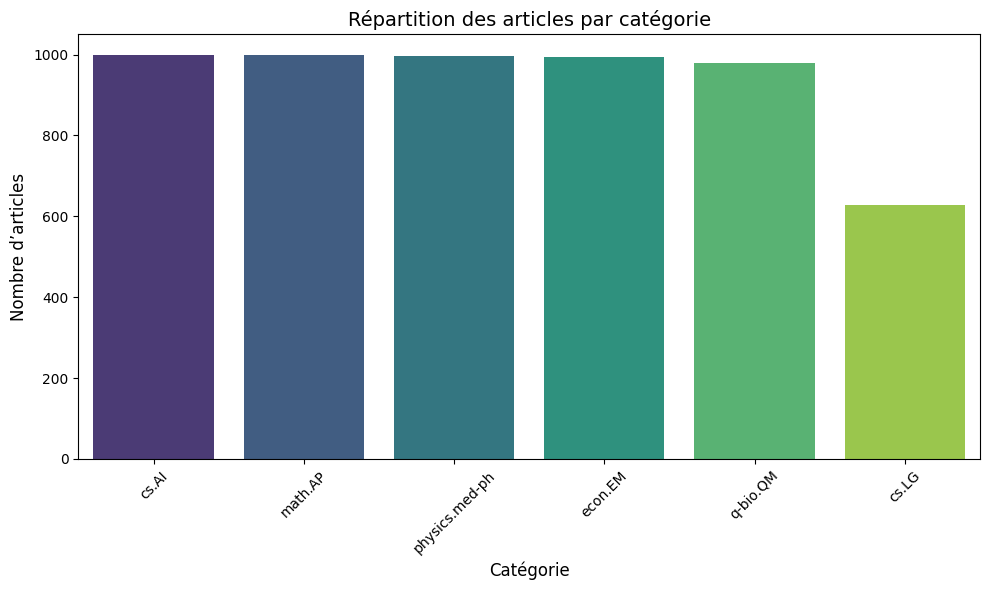

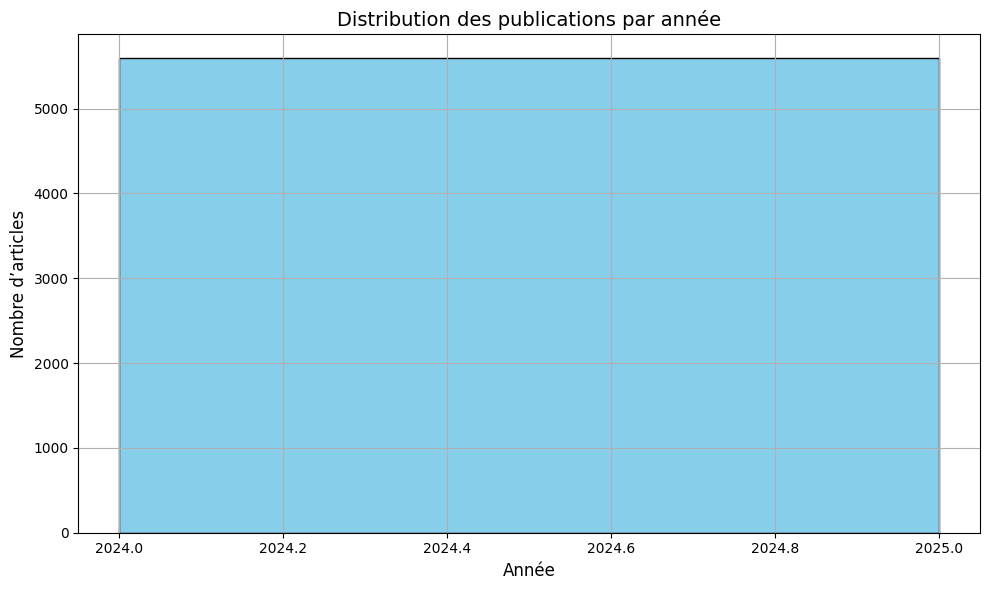

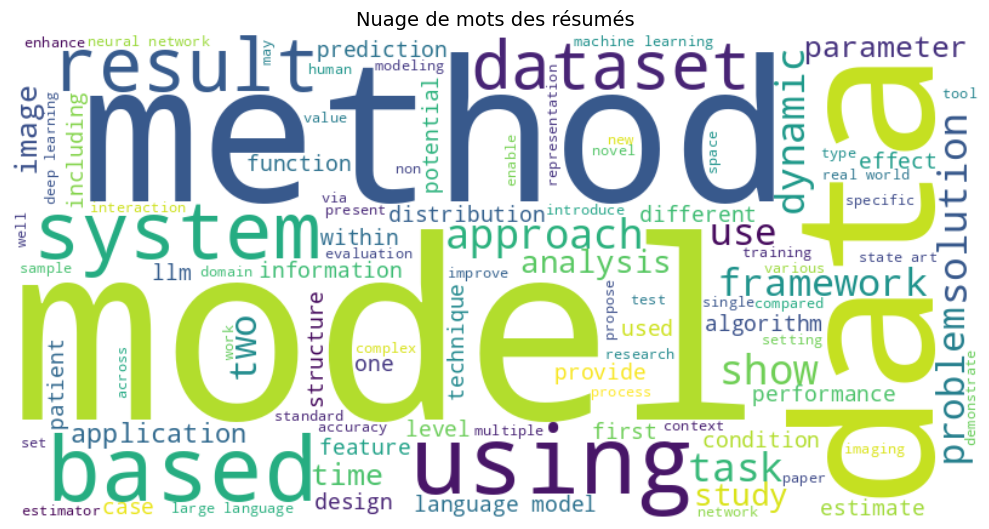

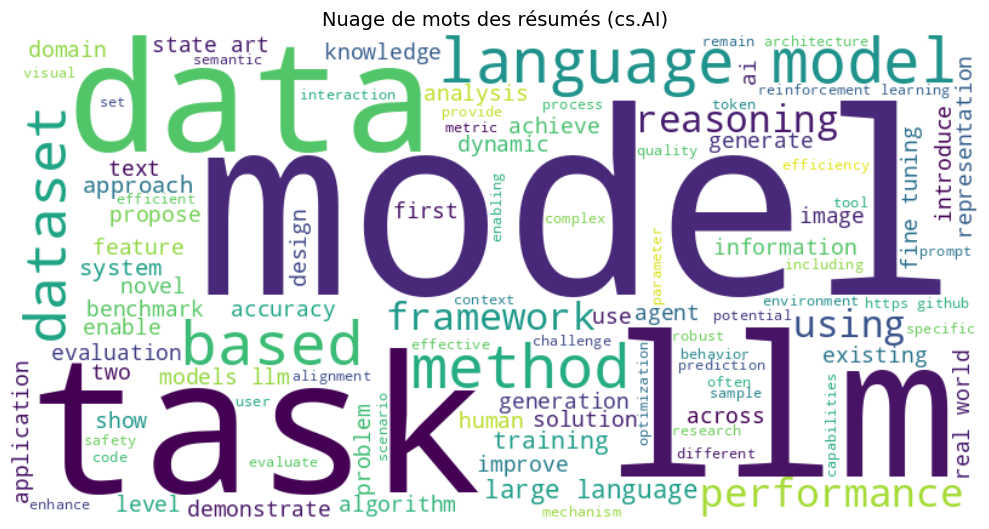

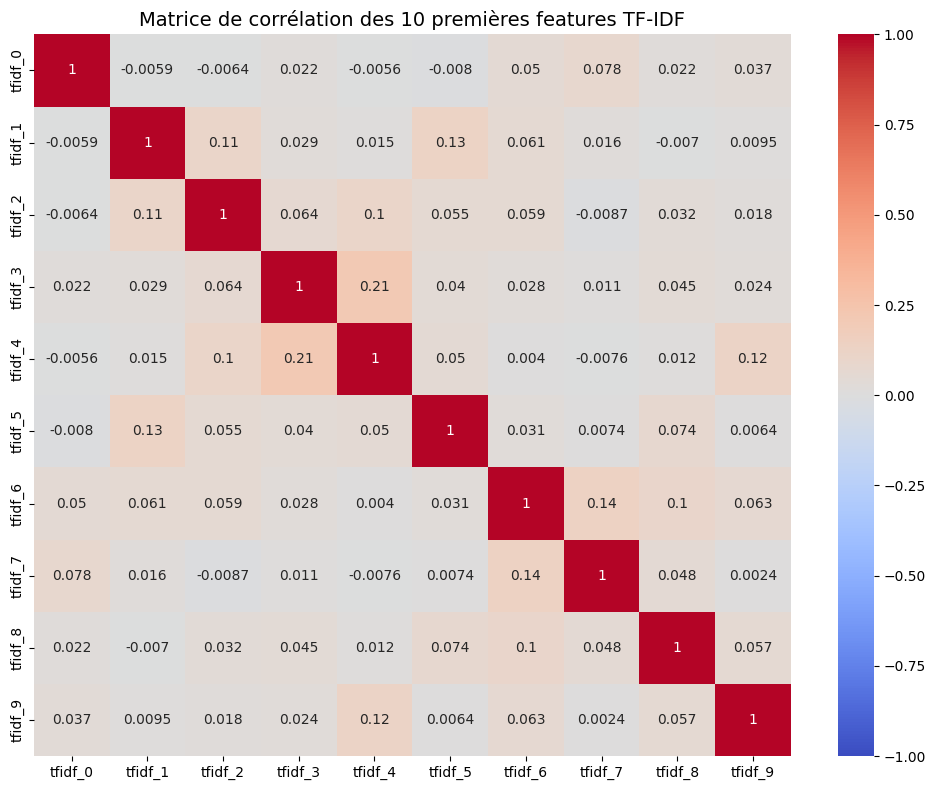

"\nfrom sklearn.svm import SVC\nfrom sklearn.ensemble import RandomForestClassifier\nfrom sklearn.metrics import accuracy_score\n\nmodels = {\n    'XGBoost': XGBClassifier(max_depth=6, learning_rate=0.3, n_estimators=100, random_state=42),\n    'SVM': SVC(kernel='linear', random_state=42),\n    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)\n}\naccuracies = []\nfor name, model in models.items():\n    model.fit(X_train, y_train)\n    y_pred = model.predict(X_test)\n    accuracies.append(accuracy_score(y_test, y_pred))\n\nplt.figure(figsize=(8, 6))\nsns.barplot(x=accuracies, y=list(models.keys()), palette='muted')\nplt.title('Comparaison des performances des modèles', fontsize=14)\nplt.xlabel('Précision', fontsize=12)\nplt.ylabel('Modèle', fontsize=12)\nplt.xlim(0, 1)\nplt.tight_layout()\nplt.savefig('model_performance.png')\nplt.show()\n"

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import nltk
nltk.download('punkt')

# Charger les données prétraitées
input_file = "arxiv_preprocessed_20250527.csv"  # Remplacer par le nom de votre fichier
try:
    df = pd.read_csv(input_file)
except FileNotFoundError:
    print(f"Erreur : Le fichier {input_file} n'existe pas.")
    exit()

# 1. Histogramme de la répartition des articles par catégorie
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='category', order=df['category'].value_counts().index, palette='viridis')
plt.title('Répartition des articles par catégorie', fontsize=14)
plt.xlabel('Catégorie', fontsize=12)
plt.ylabel('Nombre d’articles', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('category_distribution.png')
plt.show()

# 2. Histogramme de la distribution temporelle des publications
if 'year' in df.columns:
    plt.figure(figsize=(10, 6))
    df['year'].hist(bins=range(int(df['year'].min()), int(df['year'].max()) + 1), color='skyblue', edgecolor='black')
    plt.title('Distribution des publications par année', fontsize=14)
    plt.xlabel('Année', fontsize=12)
    plt.ylabel('Nombre d’articles', fontsize=12)
    plt.tight_layout()
    plt.savefig('year_distribution.png')
    plt.show()
else:
    print("Colonne 'year' manquante. Vérifiez le prétraitement.")

# 3. Nuage de mots des termes fréquents dans les résumés
if 'abstract_clean' in df.columns:
    all_abstracts = ' '.join(df['abstract_clean'].dropna())
    wordcloud = WordCloud(width=800, height=400, background_color='white', max_words=100).generate(all_abstracts)
    plt.figure(figsize=(10, 6))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title('Nuage de mots des résumés', fontsize=14)
    plt.axis('off')
    plt.tight_layout()
    plt.savefig('wordcloud_abstracts.png')
    plt.show()

    # Nuage de mots pour cs.AI (exemple)
    cs_ai_abstracts = ' '.join(df[df['category'] == 'cs.AI']['abstract_clean'].dropna())
    if cs_ai_abstracts:
        wordcloud_cs_ai = WordCloud(width=800, height=400, background_color='white', max_words=100).generate(cs_ai_abstracts)
        plt.figure(figsize=(10, 6))
        plt.imshow(wordcloud_cs_ai, interpolation='bilinear')
        plt.title('Nuage de mots des résumés (cs.AI)', fontsize=14)
        plt.axis('off')
        plt.tight_layout()
        plt.savefig('wordcloud_cs_ai.png')
        plt.show()
else:
    print("Colonne 'abstract_clean' manquante. Vérifiez le prétraitement.")

# 4. Matrice de corrélation des features TF-IDF
tfidf_cols = [col for col in df.columns if col.startswith('tfidf_')]
if len(tfidf_cols) > 0:
    plt.figure(figsize=(10, 8))
    corr_matrix = df[tfidf_cols[:10]].corr()  # Limiter à 10 features pour lisibilité
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
    plt.title('Matrice de corrélation des 10 premières features TF-IDF', fontsize=14)
    plt.tight_layout()
    plt.savefig('tfidf_correlation.png')
    plt.show()
else:
    print("Colonnes TF-IDF manquantes. Vérifiez le prétraitement.")

# 5. Matrice de confusion (commentée, nécessite un modèle entraîné)
"""
from sklearn.metrics import confusion_matrix
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split

X = df[[col for col in df.columns if col.startswith('tfidf_')]].fillna(0)
y = df['category_encoded']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

xgb_model = XGBClassifier(max_depth=6, learning_rate=0.3, n_estimators=100, random_state=42)
xgb_model.fit(X_train, y_train)
y_pred = xgb_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=df['category'].unique(), yticklabels=df['category'].unique())
plt.title('Matrice de confusion pour XGBoost', fontsize=14)
plt.xlabel('Prédictions', fontsize=12)
plt.ylabel('Vraies étiquettes', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('confusion_matrix_xgboost.png')
plt.show()
"""

# 6. Graphique en barres des performances des modèles (commentée, nécessite des modèles entraînés)
"""
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

models = {
    'XGBoost': XGBClassifier(max_depth=6, learning_rate=0.3, n_estimators=100, random_state=42),
    'SVM': SVC(kernel='linear', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}
accuracies = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracies.append(accuracy_score(y_test, y_pred))

plt.figure(figsize=(8, 6))
sns.barplot(x=accuracies, y=list(models.keys()), palette='muted')
plt.title('Comparaison des performances des modèles', fontsize=14)
plt.xlabel('Précision', fontsize=12)
plt.ylabel('Modèle', fontsize=12)
plt.xlim(0, 1)
plt.tight_layout()
plt.savefig('model_performance.png')
plt.show()
"""

In [ ]:
pip install scikit-learn tensorflow transformers


In [ ]:
#1. Logistic Regression + TF-IDF
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

X = df['title'] + " " + df['abstract']
y = df['category']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, stop_words='english')),
    ('clf', LogisticRegression(max_iter=1000, multi_class='multinomial'))
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

print(classification_report(y_test, y_pred))

##teste du module
# Exemple de résumé/article
new_text = "In this paper, we propose a novel approach using deep reinforcement learning to solve control tasks."

# Tester le modèle
domain, confidence = classifier.classify_new(new_text)

print(f"Ce texte est classé comme: {domain} avec une confiance de {confidence:.2%}")


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


                precision    recall  f1-score   support

         cs.AI       0.72      0.82      0.76       220
         cs.LG       0.53      0.39      0.45       134
       econ.EM       0.91      0.93      0.92       188
       math.AP       0.94      0.96      0.95       188
physics.med-ph       0.88      0.87      0.87       202
      q-bio.QM       0.80      0.78      0.79       188

      accuracy                           0.81      1120
     macro avg       0.79      0.79      0.79      1120
  weighted avg       0.81      0.81      0.81      1120

Classification: AppliedMath (Confiance: 91.81%)

Mots les plus influents:
- approach: 0.299
- 2025: 0.261
- arbitrarily: 0.232
- 2009: 0.227
- 12 12: 0.212
Ce texte est classé comme: AppliedMath avec une confiance de 91.81%


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
import numpy as np

# ========== 1. قراءة الملف ==========

# غيّر اسم الملف حسب الإسم اللي عندك
df = pd.read_csv("arxiv_full_20250526.csv")

# تأكد أن الأعمدة موجودة
assert all(col in df.columns for col in ['title', 'abstract', 'category']), "خاص الأعمدة: title, abstract, category"

# ========== 2. تجهيز البيانات ==========

# ندمج العنوان + الملخص فواحد النص
df['text'] = df['title'].fillna('') + " " + df['abstract'].fillna('')

# حذف السطور اللي فيهم 'domain' مفقود
df = df.dropna(subset=['category'])

X = df['text']
y = df['category']

# ========== 3. تقسيم البيانات Train/Test ==========

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ========== 4. Vectorization TF-IDF ==========

vectorizer = TfidfVectorizer(max_features=10000, stop_words='english')
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# ========== 5. تدريب النموذج ==========

model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train)

# ========== 6. تقييم الأداء ==========

y_pred = model.predict(X_test_tfidf)
print(classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
##############✅ 3. اختبار النموذج على مقال جديد:

def predict_category(title, abstract):
    text = title + " " + abstract
    vector = vectorizer.transform([text])
    proba = model.predict_proba(vector)[0]
    prediction = model.predict(vector)[0]
    confidence = np.max(proba) * 100

    print(f"\n📚 Classification: {prediction} (Confiance: {confidence:.2f}%)")

    # الكلمات الأكثر تأثيراً
    class_index = model.classes_.tolist().index(prediction)
    top_features = vectorizer.get_feature_names_out()
    weights = model.coef_[class_index]
    top_indices = weights.argsort()[-5:][::-1]
    print("\n🔍 Mots les plus influents:")
    for i in top_indices:
        print(f"- {top_features[i]}: {weights[i]:.3f}")

# ✅ مثال:
predict_category(
    title="Neural Networks for Pattern Recognition",
    abstract="We propose a novel convolutional architecture for time-series analysis..."
)



                precision    recall  f1-score   support

         cs.AI       0.71      0.83      0.77       220
         cs.LG       0.55      0.37      0.44       134
       econ.EM       0.91      0.94      0.92       188
       math.AP       0.94      0.96      0.95       188
physics.med-ph       0.88      0.88      0.88       202
      q-bio.QM       0.81      0.79      0.80       188

      accuracy                           0.82      1120
     macro avg       0.80      0.80      0.79      1120
  weighted avg       0.81      0.82      0.81      1120

Accuracy: 0.8178571428571428

📚 Classification: cs.LG (Confiance: 36.28%)

🔍 Mots les plus influents:
- learning: 3.116
- training: 2.224
- neural: 2.033
- tasks: 1.836
- attention: 1.714


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report
import numpy as np

# 📂 Charger le fichier CSV
df = pd.read_csv("arxiv_full_20250526.csv")  # Remplace avec le nom réel

# 🧹 Nettoyage : enlever les lignes sans texte ou catégorie
df.dropna(subset=["abstract", "category"], inplace=True)

# 🏷️ X = résumé, y = catégorie
X = df["abstract"]
y = df["category"]

# 🔤 Transformer le texte en vecteurs TF-IDF
vectorizer = TfidfVectorizer(max_features=5000)
X_vec = vectorizer.fit_transform(X)

# 🧪 Split en train/test
X_train, X_test, y_train, y_test = train_test_split(X_vec, y, test_size=0.2, random_state=42)

# 🌲 Créer et entraîner RandomForest
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

# ✅ Prédiction
y_pred = rf.predict(X_test)

# 📊 Évaluation
print(classification_report(y_test, y_pred))

# 🧪 Exemple d'article à tester
test_text = ["We propose a novel neural network for transfer learning with attention mechanisms."]

# 🧠 Transformer le texte comme les données d'entraînement
test_vec = vectorizer.transform(test_text)

# 🔍 Prédiction
pred = rf.predict(test_vec)
proba = rf.predict_proba(test_vec)

# 🖨️ Résultat
print(f"Catégorie prédite: {pred[0]}")
print("Probabilité pour chaque classe :")

for label, prob in zip(rf.classes_, proba[0]):
    print(f" - {label}: {prob:.2%}")



                precision    recall  f1-score   support

         cs.AI       0.65      0.83      0.73       220
         cs.LG       0.56      0.11      0.19       134
       econ.EM       0.79      0.89      0.84       188
       math.AP       0.89      0.97      0.93       188
physics.med-ph       0.78      0.87      0.82       202
      q-bio.QM       0.73      0.66      0.69       188

      accuracy                           0.76      1120
     macro avg       0.73      0.72      0.70      1120
  weighted avg       0.74      0.76      0.73      1120

Catégorie prédite: math.AP
Probabilité pour chaque classe :
 - cs.AI: 18.50%
 - cs.LG: 19.50%
 - econ.EM: 14.50%
 - math.AP: 29.50%
 - physics.med-ph: 6.00%
 - q-bio.QM: 12.00%


In [ ]:
print(df.columns)


Index(['id', 'title', 'abstract', 'published', 'category'], dtype='object')


In [ ]:
 ###########3. Support Vector Machine (SVM)
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report
from sklearn.pipeline import Pipeline

# 1. Charger le fichier CSV
df = pd.read_csv("arxiv_full_20250526.csv")  # 🛠️ Remplace par le vrai nom

# 2. Vérifier les colonnes
print(df.columns)

# 3. Supprimer les lignes sans résumé ni catégorie
df.dropna(subset=['abstract', 'category'], inplace=True)

# 4. Fusionner title + abstract comme texte d’entrée
df['text'] = df['title'] + " " + df['abstract']

# 5. Diviser le dataset
X_train, X_test, y_train, y_test = train_test_split(df['text'], df['category'], test_size=0.2, random_state=42)

# 6. Créer le pipeline (TF-IDF + SVM)
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000)),
    ('svm', LinearSVC())
])

# 7. Entraîner le modèle
pipeline.fit(X_train, y_train)

# 8. Évaluer les performances
y_pred = pipeline.predict(X_test)
print("\n📊 Rapport de classification :\n")
print(classification_report(y_test, y_pred))

# 9. Tester avec un exemple personnalisé
example = "We propose a neural network approach for learning in intelligent systems."
prediction = pipeline.predict([example])[0]

print(f"\n🧠 Exemple testé :\nTexte : {example}")
print(f"✅ Catégorie prédite : {prediction}")


Index(['id', 'title', 'abstract', 'published', 'category'], dtype='object')

📊 Rapport de classification :

                precision    recall  f1-score   support

         cs.AI       0.72      0.80      0.76       220
         cs.LG       0.50      0.42      0.46       134
       econ.EM       0.93      0.93      0.93       188
       math.AP       0.96      0.97      0.97       188
physics.med-ph       0.88      0.89      0.88       202
      q-bio.QM       0.78      0.76      0.77       188

      accuracy                           0.81      1120
     macro avg       0.79      0.79      0.79      1120
  weighted avg       0.81      0.81      0.81      1120


🧠 Exemple testé :
Texte : We propose a neural network approach for learning in intelligent systems.
✅ Catégorie prédite : cs.LG


In [ ]:
##########4. Naive Bayes (MultinomialNB) 6. Transformers (BERT) avec Hugging Face (exemple simple)



import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report
from sklearn.pipeline import make_pipeline

# 📥 1. Charger les données
df = pd.read_csv("arxiv_full_20250526.csv")  # Remplace par le nom exact du fichier

# 🧹 2. Nettoyer : garder seulement les colonnes nécessaires et retirer les lignes vides
df = df[['title', 'abstract', 'category']].dropna()

# 📝 3. Créer une seule colonne texte combinée
df['text'] = df['title'] + " " + df['abstract']

# 🎯 4. Séparer les features et les labels
X = df['text']
y = df['category']

# 🔀 5. Diviser en données d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 🤖 6. Créer un pipeline avec TF-IDF + Multinomial Naive Bayes
model = make_pipeline(TfidfVectorizer(), MultinomialNB())

# 🚀 7. Entraîner le modèle
model.fit(X_train, y_train)

# 📊 8. Évaluer le modèle
y_pred = model.predict(X_test)
print("\n📊 Rapport de classification :\n")
print(classification_report(y_test, y_pred))

# 🧠 9. Tester avec un exemple personnalisé
example_text = "We propose a neural network approach for learning in intelligent systems."
predicted_category = model.predict([example_text])[0]
probabilities = model.predict_proba([example_text])[0]
class_labels = model.classes_

print(f"\n🧠 Exemple testé :\nTexte : {example_text}")
print(f"✅ Catégorie prédite : {predicted_category}")
print("\n📈 Probabilités par catégorie :")
for label, prob in zip(class_labels, probabilities):
    print(f" - {label}: {prob*100:.2f}%")



📊 Rapport de classification :

                precision    recall  f1-score   support

         cs.AI       0.63      0.93      0.75       220
         cs.LG       0.00      0.00      0.00       134
       econ.EM       0.83      0.95      0.89       188
       math.AP       0.94      0.97      0.96       188
physics.med-ph       0.91      0.88      0.89       202
      q-bio.QM       0.80      0.82      0.81       188

      accuracy                           0.80      1120
     macro avg       0.69      0.76      0.72      1120
  weighted avg       0.72      0.80      0.75      1120


🧠 Exemple testé :
Texte : We propose a neural network approach for learning in intelligent systems.
✅ Catégorie prédite : q-bio.QM

📈 Probabilités par catégorie :
 - cs.AI: 28.33%
 - cs.LG: 15.47%
 - econ.EM: 10.89%
 - math.AP: 2.45%
 - physics.med-ph: 9.62%
 - q-bio.QM: 33.23%


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
######## 5. Deep Learning (LSTM) — Exemple simple avec Keras
import pandas as pd
import numpy as np
import re
import nltk
from nltk.corpus import stopwords
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping

# --- 1. Chargement des données ---
# Remplace cette ligne par ton chargement réel
# df = pd.read_csv('tes_donnees.csv')

# Pour l'exemple, supposons que df a bien les colonnes suivantes:
# ['id', 'title', 'abstract', 'published', 'category']
df = pd.read_csv("arxiv_full_20250526.csv")  # Remplace par le nom exact du fichier

# --- 2. Nettoyage du texte ---
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

def clean_text(text):
    if pd.isna(text):
        return ""
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)  # enlever ponctuation et chiffres
    tokens = text.split()
    tokens = [w for w in tokens if w not in stop_words]
    return " ".join(tokens)

# Combiner title + abstract pour plus d'infos
df['text'] = df['title'].fillna('') + " " + df['abstract'].fillna('')
df['clean_text'] = df['text'].apply(clean_text)

# --- 3. Préparation des données pour le modèle ---

max_words = 10000   # taille du vocabulaire
max_len = 300       # longueur max des séquences

tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(df['clean_text'])

sequences = tokenizer.texts_to_sequences(df['clean_text'])
X = pad_sequences(sequences, maxlen=max_len, padding='post')

# Encoder les catégories
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df['category'])
y = to_categorical(y)

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# --- 4. Construction du modèle LSTM ---

num_classes = y.shape[1]

model = Sequential()
model.add(Embedding(input_dim=max_words, output_dim=128))  # embedding layer
model.add(LSTM(128, return_sequences=True))
model.add(LSTM(64))
model.add(Dropout(0.3))
model.add(Dense(64, activation='relu'))
model.add(Dense(num_classes, activation='softmax'))

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# --- 5. Entraînement avec EarlyStopping ---

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(X_train, y_train,
                    epochs=15, batch_size=32,
                    validation_split=0.1,
                    callbacks=[early_stop])

# --- 6. Évaluation sur le test ---

loss, accuracy = model.evaluate(X_test, y_test)
print(f"\n📊 Test Accuracy: {accuracy*100:.2f}%")

# --- 7. Exemple de prédiction ---

def predict_category(text):
    text_clean = clean_text(text)
    seq = tokenizer.texts_to_sequences([text_clean])
    padded = pad_sequences(seq, maxlen=max_len, padding='post')
    pred = model.predict(padded)[0]
    idx = np.argmax(pred)
    cat = label_encoder.inverse_transform([idx])[0]
    print("\n🧠 Texte :", text)
    print("✅ Catégorie prédite :", cat)
    print("📈 Probabilités par catégorie :")
    for i, p in enumerate(pred):
        print(f" - {label_encoder.inverse_transform([i])[0]}: {p*100:.2f}%")

# Test
predict_category("We propose a neural network approach for learning in intelligent systems.")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Epoch 1/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 106s 789ms/step - accuracy: 0.1827 - loss: 1.7869 - val_accuracy: 0.1429 - val_loss: 1.7782
Epoch 2/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 141s 782ms/step - accuracy: 0.1783 - loss: 1.7830 - val_accuracy: 0.2009 - val_loss: 1.7758
Epoch 3/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 148s 833ms/step - accuracy: 0.1712 - loss: 1.7851 - val_accuracy: 0.1920 - val_loss: 1.7725
Epoch 4/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 139s 813ms/step - accuracy: 0.1765 - loss: 1.7814 - val_accuracy: 0.1429 - val_loss: 1.7762
Epoch 5/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 137s 774ms/step - accuracy: 0.1859 - loss: 1.7833 - val_accuracy: 0.1429 - val_loss: 1.7752
Epoch 6/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 144s 791ms/step - accuracy: 0.1692 - loss: 1.7820 - val_accuracy: 0.1429 - val_loss: 1.7744
35/35 ━━━━━━━━━━━━━━━━━━━━ 8s 241ms/step - accuracy: 0.1748 - loss: 1.7779

📊 Test Accuracy: 17.86%
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step

🧠 Texte : We propose a neural network approach for learning in intel

Fichier chargé avec succès : 5596 articles.

Entraînement de XGBoost...
Précision de XGBoost : 0.80
              precision    recall  f1-score   support

           0       0.71      0.80      0.75       220
           1       0.54      0.37      0.44       134
           2       0.86      0.91      0.89       188
           3       0.96      0.95      0.96       188
           4       0.86      0.86      0.86       202
           5       0.75      0.75      0.75       188

    accuracy                           0.80      1120
   macro avg       0.78      0.78      0.77      1120
weighted avg       0.79      0.80      0.79      1120



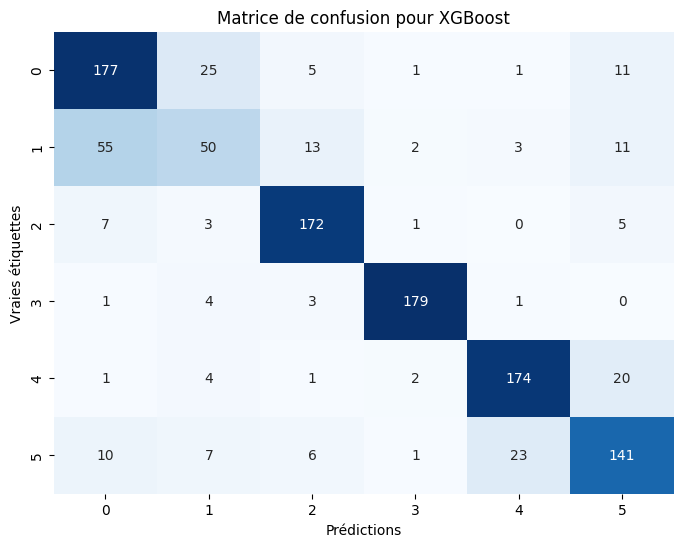


Entraînement de SVM...
Précision de SVM : 0.82
              precision    recall  f1-score   support

           0       0.72      0.80      0.76       220
           1       0.51      0.47      0.49       134
           2       0.94      0.90      0.92       188
           3       0.97      0.96      0.97       188
           4       0.88      0.87      0.88       202
           5       0.79      0.78      0.79       188

    accuracy                           0.82      1120
   macro avg       0.80      0.80      0.80      1120
weighted avg       0.82      0.82      0.82      1120



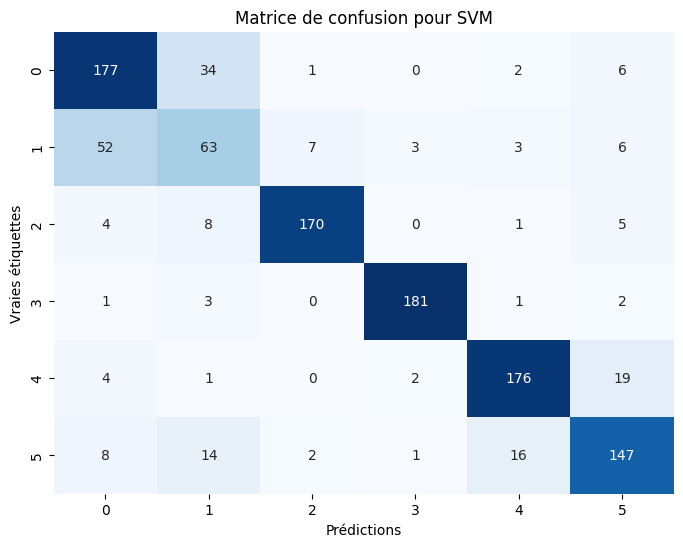


Entraînement de Random Forest...
Précision de Random Forest : 0.77
              precision    recall  f1-score   support

           0       0.66      0.85      0.74       220
           1       0.56      0.17      0.26       134
           2       0.80      0.91      0.85       188
           3       0.93      0.96      0.95       188
           4       0.80      0.88      0.83       202
           5       0.77      0.67      0.72       188

    accuracy                           0.77      1120
   macro avg       0.75      0.74      0.72      1120
weighted avg       0.76      0.77      0.75      1120



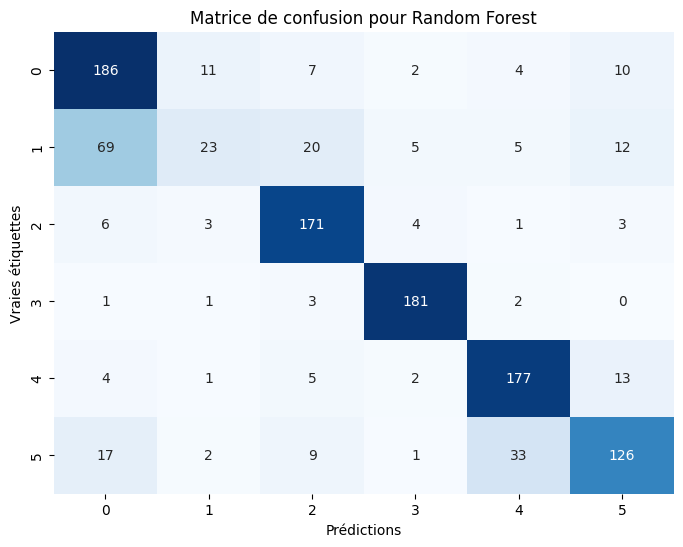

<ipython-input-8-c22580e54f62>:58: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(results.values()), y=list(results.keys()), palette='viridis')


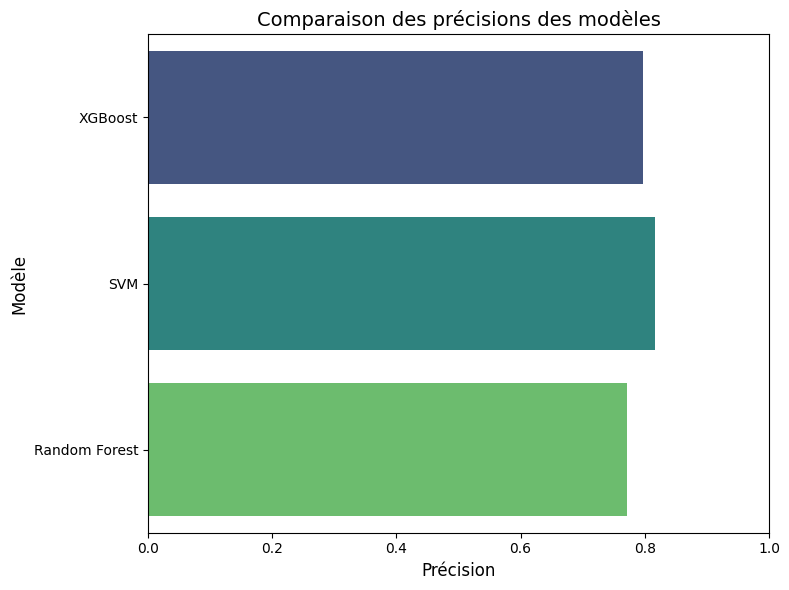


Résultats sauvegardés dans model_results.csv


In [ ]:
#####entrainement du modéle
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Charger les données suréchantillonnées
input_file = "arxiv_preprocessed_20250527.csv"  # Ajustez selon le nom de votre fichier
try:
    df = pd.read_csv(input_file)
    print(f"Fichier chargé avec succès : {len(df)} articles.")
except FileNotFoundError:
    print(f"Erreur : Le fichier {input_file} n'existe pas.")
    exit()

# Préparer les données
X = df[[col for col in df.columns if col.startswith('tfidf_')]].fillna(0)  # Features TF-IDF
y = df['category_encoded']  # Classes

# Diviser en ensembles d'entraînement et de test (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialiser les modèles
models = {
    'XGBoost': XGBClassifier(max_depth=6, learning_rate=0.3, n_estimators=100, random_state=42),
    'SVM': SVC(kernel='linear', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

# Entraîner et évaluer chaque modèle
results = {}
for name, model in models.items():
    print(f"\nEntraînement de {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    results[name] = accuracy
    print(f"Précision de {name} : {accuracy:.2f}")
    print(classification_report(y_test, y_pred))

    # Matrice de confusion
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'Matrice de confusion pour {name}')
    plt.xlabel('Prédictions')
    plt.ylabel('Vraies étiquettes')
    plt.savefig(f'confusion_matrix_{name.lower()}.png')
    plt.show()

# Comparaison des performances
plt.figure(figsize=(8, 6))
sns.barplot(x=list(results.values()), y=list(results.keys()), palette='viridis')
plt.title('Comparaison des précisions des modèles', fontsize=14)
plt.xlabel('Précision', fontsize=12)
plt.ylabel('Modèle', fontsize=12)
plt.xlim(0, 1)
plt.tight_layout()
plt.savefig('model_performance_comparison.png')
plt.show()

# Sauvegarder les résultats
results_df = pd.DataFrame(list(results.items()), columns=['Model', 'Accuracy'])
results_df.to_csv('model_results.csv', index=False)
print("\nRésultats sauvegardés dans model_results.csv")

In [ ]:
import pandas as pd
import numpy as np
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
import re
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import nltk
import pickle

# Télécharger toutes les ressources NLTK nécessaires
nltk.download('punkt')
nltk.download('punkt_tab')  # Ajout pour résoudre l'erreur
nltk.download('stopwords')

# Charger les données suréchantillonnées pour ajuster le vectoriseur
input_file = "arxiv_preprocessed_20250527.csv"  # Ajustez selon le nom de votre fichier
try:
    df = pd.read_csv(input_file)
    print(f"Fichier chargé avec succès : {len(df)} articles.")
except FileNotFoundError:
    print(f"Erreur : Le fichier {input_file} n'existe pas.")
    exit()

# Préparer les données pour ré-entraîner rapidement si nécessaire
X = df[[col for col in df.columns if col.startswith('tfidf_')]].fillna(0)
y = df['category_encoded']

# Ré-entraîner les modèles (si non sauvegardés)
models = {
    'XGBoost': XGBClassifier(max_depth=6, learning_rate=0.3, n_estimators=100, random_state=42),
    'SVM': SVC(kernel='linear', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

# Entraîner les modèles
for name, model in models.items():
    print(f"\nEntraînement de {name}...")
    model.fit(X, y)
    # Sauvegarder le modèle (optionnel)
    with open(f"{name.lower()}_model.pkl", 'wb') as f:
        pickle.dump(model, f)

# Fonction pour prétraiter un texte
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    text = str(text)
    text = re.sub(r'[^\w\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    text = text.lower().strip()
    tokens = word_tokenize(text)
    filtered_tokens = [word for word in tokens if word not in stop_words and len(word) > 1]
    return ' '.join(filtered_tokens) if filtered_tokens else text

# Exemple de phrase/résumé fictif
new_abstract = "This study proposes a new machine learning algorithm for optimizing neural networks in predictive modeling, achieving high accuracy on benchmark datasets."

# Prétraiter le texte
new_text_clean = preprocess_text(new_abstract)
print(f"\nTexte prétraité : {new_text_clean}")

# Vectorisation TF-IDF
abstracts_train = df['abstract_clean'].fillna('MISSING_ABSTRACT')
vectorizer = TfidfVectorizer(max_features=5000, min_df=5, max_df=0.8, ngram_range=(1, 2))
vectorizer.fit(abstracts_train)
new_text_tfidf = vectorizer.transform([new_text_clean])
new_text_df = pd.DataFrame(new_text_tfidf.toarray(), columns=vectorizer.get_feature_names_out())

# S'assurer que les colonnes correspondent à celles de X
missing_cols = [col for col in X.columns if col not in new_text_df.columns]
for col in missing_cols:
    new_text_df[col] = 0
new_text_df = new_text_df[X.columns]  # Réordonner les colonnes

# Prédire la catégorie avec chaque modèle
category_mapping = {0: 'cs.AI', 1: 'econ.EM', 2: 'cs.LG', 3: 'math.AP', 4: 'physics.med-ph', 5: 'q-bio.QM'}
print("\nPrédictions pour le résumé fictif :")
for name, model in models.items():
    prediction = model.predict(new_text_df)[0]
    predicted_category = category_mapping[prediction]
    print(f"{name} prédit la catégorie : {predicted_category}")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Fichier chargé avec succès : 5596 articles.

Entraînement de XGBoost...

Entraînement de SVM...

Entraînement de Random Forest...

Texte prétraité : study proposes new machine learning algorithm optimizing neural networks predictive modeling achieving high accuracy benchmark datasets

Prédictions pour le résumé fictif :
XGBoost prédit la catégorie : cs.LG
SVM prédit la catégorie : cs.LG
Random Forest prédit la catégorie : cs.LG


In [ ]:
import pandas as pd
import numpy as np
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
import re
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import nltk
import pickle

# Télécharger toutes les ressources NLTK nécessaires
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

# Charger les données suréchantillonnées
input_file = "arxiv_preprocessed_20250527.csv"  # Ajustez selon le nom de votre fichier
try:
    df = pd.read_csv(input_file)
    print(f"Fichier chargé avec succès : {len(df)} articles.")
except FileNotFoundError:
    print(f"Erreur : Le fichier {input_file} n'existe pas.")
    exit()

# Préparer les données
X = df[[col for col in df.columns if col.startswith('tfidf_')]].fillna(0)
y = df['category_encoded']

# Ré-entraîner les modèles
models = {
    'XGBoost': XGBClassifier(max_depth=6, learning_rate=0.3, n_estimators=100, random_state=42),
    'SVM': SVC(kernel='linear', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

for name, model in models.items():
    print(f"\nEntraînement de {name}...")
    model.fit(X, y)
    with open(f"{name.lower()}_model.pkl", 'wb') as f:
        pickle.dump(model, f)

# Fonction pour prétraiter un texte
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    text = str(text)
    text = re.sub(r'[^\w\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    text = text.lower().strip()
    tokens = word_tokenize(text)
    filtered_tokens = [word for word in tokens if word not in stop_words and len(word) > 1]
    return ' '.join(filtered_tokens) if filtered_tokens else text

# Nouvel exemple de résumé fictif (ambigu : machine learning + économie)
new_abstract = "This study explores a machine learning model to predict economic trends using neural networks and financial datasets, improving investment strategies."

# Prétraiter le texte
new_text_clean = preprocess_text(new_abstract)
print(f"\nTexte prétraité : {new_text_clean}")

# Vectorisation TF-IDF
abstracts_train = df['abstract_clean'].fillna('MISSING_ABSTRACT')
vectorizer = TfidfVectorizer(max_features=5000, min_df=5, max_df=0.8, ngram_range=(1, 2))
vectorizer.fit(abstracts_train)
new_text_tfidf = vectorizer.transform([new_text_clean])
new_text_df = pd.DataFrame(new_text_tfidf.toarray(), columns=vectorizer.get_feature_names_out())

# S'assurer que les colonnes correspondent à celles de X
missing_cols = [col for col in X.columns if col not in new_text_df.columns]
for col in missing_cols:
    new_text_df[col] = 0
new_text_df = new_text_df[X.columns]

# Prédire la catégorie avec chaque modèle
category_mapping = {0: 'cs.AI', 1: 'econ.EM', 2: 'cs.LG', 3: 'math.AP', 4: 'physics.med-ph', 5: 'q-bio.QM'}
print("\nPrédictions pour le résumé fictif ambigu :")
for name, model in models.items():
    prediction = model.predict(new_text_df)[0]
    predicted_category = category_mapping[prediction]
    print(f"{name} prédit la catégorie : {predicted_category}")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Fichier chargé avec succès : 5596 articles.

Entraînement de XGBoost...

Entraînement de SVM...

Entraînement de Random Forest...

Texte prétraité : study explores machine learning model predict economic trends using neural networks financial datasets improving investment strategies


Le flux de sortie a été tronqué et ne contient que les 5000 dernières lignes.
<ipython-input-7-5e8fe0b0f2c6>:73: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  new_text_df[col] = 0
<ipython-input-7-5e8fe0b0f2c6>:73: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  new_text_df[col] = 0
<ipython-input-7-5e8fe0b0f2c6>:73: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. 


Prédictions pour le résumé fictif ambigu :
XGBoost prédit la catégorie : cs.LG
SVM prédit la catégorie : cs.LG
Random Forest prédit la catégorie : cs.LG


In [ ]:
pip install streamlit

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 59.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 70.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 6.3 MB/s eta 0:00:00


In [ ]:
#############Vectorisation
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
import pickle

# Charger vos données (adaptez le chemin)
data = pd.read_csv('arxiv_preprocessed_20250527.csv')  # Remplacez par votre fichier CSV
X_raw = data['abstract_clean']  # Colonne des résumés
y = data['category'].map({'cs.AI': 0, 'econ.EM': 1, 'cs.LG': 2, 'math.AP': 3, 'physics.med-ph': 4, 'q-bio.QM': 5})

# Prétraitement (simplifié, adaptez selon votre logique)
def preprocess_text(text):
    text = text.lower()
    # Ajoutez ici votre logique de nettoyage (ex. : NLTK stopwords)
    return text

X_cleaned = X_raw.apply(preprocess_text)

# Vectorisation TF-IDF
vectorizer = TfidfVectorizer(max_features=5000, min_df=5, max_df=0.8)
X = vectorizer.fit_transform(X_cleaned)
X_df = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())

# Sauvegarder le vectorizer et les colonnes
pickle.dump(vectorizer, open('tfidf_vectorizer.pkl', 'wb'))
pickle.dump(X_df.columns, open('training_columns.pkl', 'wb'))

# Télécharger les fichiers
from google.colab import files
files.download('tfidf_vectorizer.pkl')
files.download('training_columns.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Étape 1 : Installer Streamlit et pyngrok
!pip install streamlit pyngrok -q

# Étape 2 : Vérifier et ajuster les fichiers existants dans /content/
import os
import shutil

# Liste des fichiers attendus
expected_files = {
    'xgboost_model.pkl': 'xgboost_model.pkl',
    'svm_model.pkl': 'svm_model.pkl',
    'rf_model.pkl': 'random forest_model.pkl',  # Ajustement du nom
    'tfidf_vectorizer.pkl': 'tfidf_vectorizer.pkl',
    'training_columns.pkl': 'training_columns.pkl'
}

# Vérifier et renommer si nécessaire
for expected, actual in expected_files.items():
    if actual in os.listdir('/content/') and expected != actual:
        shutil.move(f'/content/{actual}', f'/content/{expected}')
        print(f"Renommé : {actual} -> {expected}")
    elif expected not in os.listdir('/content/'):
        print(f"Erreur : {expected} n'est pas présent dans /content/.")
        raise SystemExit("Veuillez téléverser manuellement les fichiers manquants.")

# Vérifier les fichiers après ajustement
print("Fichiers dans /content/ après ajustement :", os.listdir('/content/'))

# Étape 3 : Créer le script Streamlit avec un design amélioré
with open('app.py', 'w') as f:
    f.write('''
import streamlit as st
import pickle
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

# Configuration de la page
st.set_page_config(
    page_title="Prédiction de Domaine d'Article",
    page_icon="📚",
    layout="wide",
    initial_sidebar_state="expanded"
)

# Style CSS personnalisé
st.markdown("""
    <style>
    body {
        background-color: #f0f2f6;
        font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;
    }
    .main {
        background: linear-gradient(135deg, #1e3c72 0%, #2a5298 100%);
        padding: 20px;
        border-radius: 15px;
        box-shadow: 0 8px 20px rgba(0, 0, 0, 0.2);
        color: white;
    }
    .stTextArea textarea {
        background-color: #ffffff;
        border: 2px solid #2a5298;
        border-radius: 10px;
        padding: 15px;
        font-size: 16px;
        color: #333;
        box-shadow: inset 0 2px 5px rgba(0, 0, 0, 0.1);
    }
    .stSelectbox select {
        background-color: #ffffff;
        border: 2px solid #2a5298;
        border-radius: 10px;
        padding: 10px;
        font-size: 16px;
        color: #333;
    }
    .stButton button {
        background: linear-gradient(90deg, #ff7e5f 0%, #feb47b 100%);
        border: none;
        border-radius: 25px;
        padding: 12px 30px;
        font-size: 16px;
        font-weight: bold;
        color: white;
        box-shadow: 0 4px 10px rgba(0, 0, 0, 0.2);
        transition: transform 0.1s ease;
    }
    .stButton button:hover {
        transform: scale(1.05);
        background: linear-gradient(90deg, #feb47b 0%, #ff7e5f 100%);
    }
    .prediction-box {
        background: linear-gradient(135deg, #28a745 0%, #34c759 100%);
        border-radius: 15px;
        padding: 20px;
        margin-top: 20px;
        box-shadow: 0 4px 15px rgba(0, 0, 0, 0.2);
        color: white;
        font-size: 20px;
        font-weight: bold;
        text-align: center;
    }
    .footer {
        text-align: center;
        margin-top: 30px;
        font-size: 14px;
        color: #ffffff;
        opacity: 0.7;
    }
    .header {
        text-align: center;
        font-size: 36px;
        font-weight: bold;
        color: #ffffff;
        margin-bottom: 20px;
        text-shadow: 2px 2px 5px rgba(0, 0, 0, 0.3);
    }
    </style>
""", unsafe_allow_html=True)

# Conteneur principal
with st.container():
    st.markdown('<div class="header">📚 Prédiction de Domaine d\'Article Scientifique</div>', unsafe_allow_html=True)
    st.markdown('<p style="text-align: center; color: #d0d4e0; font-size: 18px;">Entrez un titre ou résumé et choisissez un modèle pour découvrir le domaine !</p>', unsafe_allow_html=True)

    # Initialisation de l'état de session
    if 'input_text' not in st.session_state:
        st.session_state.input_text = ""
    if 'prediction' not in st.session_state:
        st.session_state.prediction = None
    if 'model_selected' not in st.session_state:
        st.session_state.model_selected = None

    # Charger les modèles et vectorizer
    @st.cache_data
    def load_models_and_vectorizer():
        with open('tfidf_vectorizer.pkl', 'rb') as f:
            vectorizer = pickle.load(f)
        with open('xgboost_model.pkl', 'rb') as f:
            xgboost_model = pickle.load(f)
        with open('svm_model.pkl', 'rb') as f:
            svm_model = pickle.load(f)
        with open('rf_model.pkl', 'rb') as f:
            rf_model = pickle.load(f)
        with open('training_columns.pkl', 'rb') as f:
            training_cols = pickle.load(f)
        return vectorizer, xgboost_model, svm_model, rf_model, training_cols

    vectorizer, xgboost_model, svm_model, rf_model, training_cols = load_models_and_vectorizer()

    # Prétraitement
    def preprocess_text(text):
        text = text.lower()
        return text

    # Prédiction
    def predict_domain(model, text, vectorizer, training_cols):
        cleaned_text = preprocess_text(text)
        tfidf_input = vectorizer.transform([cleaned_text])
        tfidf_df = pd.DataFrame(tfidf_input.toarray(), columns=vectorizer.get_feature_names_out())
        missing_cols = [col for col in training_cols if col not in tfidf_df.columns]
        for col in missing_cols:
            tfidf_df[col] = 0
        tfidf_df = tfidf_df[training_cols]
        prediction = model.predict(tfidf_df)[0]
        category_mapping = {0: 'cs.AI', 1: 'econ.EM', 2: 'cs.LG', 3: 'math.AP', 4: 'physics.med-ph', 5: 'q-bio.QM'}
        return category_mapping[prediction]

    # Section 1 : Entrée du titre ou résumé
    st.markdown("### ✍️ Entrez le Titre ou Résumé")
    user_input = st.text_area("", value=st.session_state.input_text, height=200, placeholder="Exemple : This study proposes a new machine learning algorithm...")

    # Section 2 : Choix du modèle
    st.markdown("### 🛠️ Choisissez un Modèle")
    model_choice = st.selectbox("", ["Random Forest", "SVM", "XGBoost"], key="model_select")

    # Section 3 : Boutons d'action
    col1, col2 = st.columns([1, 1])
    with col1:
        if st.button("Prédire", key="predict_button"):
            if user_input.strip():
                st.session_state.input_text = user_input
                st.session_state.model_selected = model_choice
                model = rf_model if model_choice == "Random Forest" else svm_model if model_choice == "SVM" else xgboost_model
                st.session_state.prediction = predict_domain(model, user_input, vectorizer, training_cols)
            else:
                st.warning("Veuillez entrer un titre ou résumé avant de prédire.")
    with col2:
        if st.button("Réinitialiser", key="reset_button"):
            st.session_state.input_text = ""
            st.session_state.prediction = None
            st.session_state.model_selected = None
            st.experimental_rerun()

    # Section 4 : Affichage de la prédiction
    if st.session_state.prediction:
        st.markdown(f'<div class="prediction-box">🌟 Domaine prédit : {st.session_state.prediction}</div>', unsafe_allow_html=True)

    # Footer
    st.markdown('<div class="footer">Développé avec ❤️ par [Votre Nom] | 2025</div>', unsafe_allow_html=True)
''')

# Étape 4 : Télécharger et configurer ngrok
!wget https://bin.equinox.io/c/4VmDzA7iaHb/ngrok-stable-linux-amd64.zip -q
!unzip -o ngrok-stable-linux-amd64.zip -d /content/

# Étape 5 : Lancer Streamlit en arrière-plan
import os
os.environ["STREAMLIT_SERVER_PORT"] = "8501"
!nohup streamlit run app.py --server.port 8501 --server.enableCORS false --browser.serverAddress 0.0.0.0 &

# Étape 6 : Configurer et lancer ngrok
from pyngrok import ngrok
import time

# Demander le jeton ngrok
ngrok_auth_token = input("Veuillez entrer votre jeton ngrok (obtenu sur https://dashboard.ngrok.com/get-started/your-authtoken) : ")
ngrok.set_auth_token(ngrok_auth_token)

# Attendre que Streamlit démarre et connecter ngrok
time.sleep(10)
public_url = ngrok.connect(8501, bind_tls=True)
if public_url:
    print("Lien pour accéder à l'interface Streamlit :", public_url)
else:
    print("Échec de la connexion ngrok. Vérifiez votre jeton et les logs ci-dessous.")
    !cat nohup.out

Fichiers dans /content/ après ajustement : ['.config', 'rf_model.pkl', 'app.py', 'random forest_model (1).pkl', 'nohup.out', 'svm_model.pkl', 'ngrok-stable-linux-amd64.zip.3', 'ngrok', 'training_columns.pkl', 'ngrok-stable-linux-amd64.zip.1', 'tfidf_vectorizer.pkl', 'ngrok-stable-linux-amd64.zip', 'arxiv_preprocessed_20250527.csv', 'ngrok-stable-linux-amd64.zip.4', 'drive', 'xgboost_model.pkl', '.ipynb_checkpoints', 'ngrok-stable-linux-amd64.zip.2', 'sample_data']
Archive:  ngrok-stable-linux-amd64.zip
  inflating: /content/ngrok          
nohup: appending output to 'nohup.out'


KeyboardInterrupt: Interrupted by user